# Notebook 03: Exploratory Data Analysis

**Project:** Global Layoffs Intelligence · **Phase:** 3 of 6
**Input:** `data/processed/layoff_events.csv` (Phase 2 canonical table, 5,035 rows), plus `layoff_event_departments.csv`.
**Outputs:** charts in `reports/figures/03_*.png`, and the data behind every chart in `reports/eda/*.csv`, so each chart can be checked and is tested.

## Analysis rules (read these first)

| Rule | What it means for every chart |
|---|---|
| **Global vs tech** | Sections 3-8 use **only the global dataset** (high confidence). The 35 tech rows (low confidence, unknown source) are analysed **separately** in Section 9 and never added to global numbers. |
| **Events** | One row = one layoff event. **All** global rows are counted, including furloughs, possible duplicates and flagged rows. Section 8 shows what happens if you exclude them. |
| **Jobs cut** | Only *verified* headcounts exist, and they cover about **50%** of events. "Verified jobs cut" sums only those. **Missing is never 0**, and every jobs figure is shown with its coverage %. |
| **Unknown stays visible** | Missing industry and missing country appear as **Unknown**. Values that are not countries (e.g. `Arizona`) appear as **Unresolved**. |
| **2026 is partial** | The global data stops in June 2026, so 2026 is labelled *partial* and never compared as a full year. |
| **Sample** | The global file is a **26% sample** of the source's events. Counts describe the sample, not the whole market. |

These rules are coded in `src/phase3_eda.py`, and `tests/test_phase3_eda.py` checks that every chart's numbers reconcile with the canonical table.

**How to run:** use the same kernel as notebooks 01-02 (*Python (layoffs-env)*). Run notebooks 01 and 02 first, then *Run All*.

## 1. Setup and input validation

**Objective.** Load the canonical table and confirm it is exactly the file Phase 2 produced and verified.

**Concept.** Phase 2 saved a SHA-256 fingerprint of every output (`phase2_output_manifest.csv`). Matching it proves we analyse the verified data and not an edited copy.

In [1]:
from pathlib import Path
import sys
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_project_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Start Jupyter inside the project folder.")


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
EDA_DIR = PROJECT_ROOT / "reports" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
import phase3_eda as eda
print("Project root:", PROJECT_ROOT)

Project root: /home/claude/global-layoffs-intelligence


In [2]:
manifest = pd.read_csv(PROCESSED_DIR / "phase2_output_manifest.csv").set_index("file")["sha256"]
for name in ["layoff_events.csv", "layoff_event_departments.csv"]:
    now = hashlib.sha256((PROCESSED_DIR / name).read_bytes()).hexdigest()
    assert now == manifest[name], f"{name} differs from the verified Phase 2 output"
    print("verified input:", name, now[:12])

events = eda.load_events(PROCESSED_DIR / "layoff_events.csv")
departments = pd.read_csv(PROCESSED_DIR / "layoff_event_departments.csv")
g = eda.global_rows(events)      # main analysis
t = eda.tech_rows(events)        # separate, lower confidence
assert (len(g), len(t)) == (5000, 35)
assert g["employees_laid_off"].isna().sum() == 2511     # missing headcounts still missing
print(f"global rows: {len(g):,} | tech rows: {len(t)}")

verified input: layoff_events.csv 9a42f4f1a1a7
verified input: layoff_event_departments.csv 08005235def7
global rows: 5,000 | tech rows: 35


**Chart style.** All charts share one style: a light background, thin marks, a recessive grid and a single blue for one series.
Grey is reserved for **Unknown / Unresolved**, so missing data is visible but never confused with a real category.
Orange is used **only** for the tech dataset, so a tech chart is never mistaken for a global one.

In [3]:
BLUE, BLUE_LIGHT, GREY, ORANGE = "#2a78d6", "#9ec5f4", "#a3a29c", "#eb6834"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 9.5,
})


def save(fig, name, data=None):
    # save the chart AND the exact table it was drawn from
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    if data is not None:
        data.to_csv(EDA_DIR / f"{name}.csv", index=False)
    plt.show()


def barh(ax, labels, values, colors, fmt="{:,.0f}"):
    # horizontal bars, largest at the top, value printed at the end of each bar
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.7)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values):
        if pd.notna(v):
            ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=8, color=INK_2)

## 2. Layoffs over time: monthly

**Objective.** See how the number of layoff events changed month by month from 2019 to mid-2026.

**Concept.** A thin line shows each month, and a thicker line shows the **3-month rolling average**, which smooths one-off spikes so the trend is easier to read.
A month with no events would be a real 0 (it is a *count of rows*), not a missing value. In this data no month is empty.

**Watch the last two months.** May 2026 (12 events) and June 2026 (23 events, data ends 14 June) are far below earlier months. This looks like a collection lag in the source, so it should not be read as a real drop.

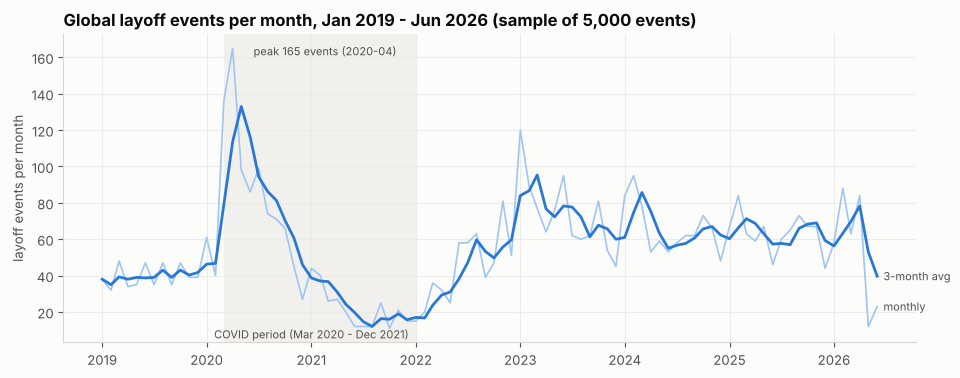

In [4]:
monthly = eda.monthly_events(g)
assert monthly["events"].sum() == len(g)

fig, ax = plt.subplots(figsize=(11, 4))
x = pd.PeriodIndex(monthly["month"], freq="M").to_timestamp()
ax.plot(x, monthly["events"], color=BLUE_LIGHT, linewidth=1.2)
ax.plot(x, monthly["events_3m_avg"], color=BLUE, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="#f1f0ec", zorder=0)
ax.text(pd.Timestamp("2021-01-01"), 4, "COVID period (Mar 2020 - Dec 2021)", fontsize=8, color=INK_2, ha="center", va="bottom")
peak = monthly.loc[monthly["events"].idxmax()]
ax.annotate(f"peak {peak['events']} events ({peak['month']})", (pd.Period(peak["month"]).to_timestamp(), peak["events"]),
            xytext=(15, -5), textcoords="offset points", fontsize=8, color=INK_2)
ax.text(x[-1], monthly["events_3m_avg"].iloc[-1], "  3-month avg", color=INK_2, fontsize=8, va="center")
ax.text(x[-1], monthly["events"].iloc[-1], "  monthly", color=INK_2, fontsize=8, va="center")
ax.set_ylabel("layoff events per month")
ax.set_title("Global layoff events per month, Jan 2019 - Jun 2026 (sample of 5,000 events)")
save(fig, "03_01_monthly_events", monthly)

## 3. Layoffs over time: yearly events and verified jobs cut

**Objective.** Compare years on two measures, the **number of events** and the **verified jobs cut**, without mixing them on one axis.

**Concept.** The two measures have very different scales, so they get **two separate charts** instead of a dual-axis chart, which can mislead.
The jobs chart prints the **coverage** above each bar (the % of that year's events with a verified headcount), because the totals only include those events.
2026 is drawn lighter because it is a partial year (Jan-Jun).

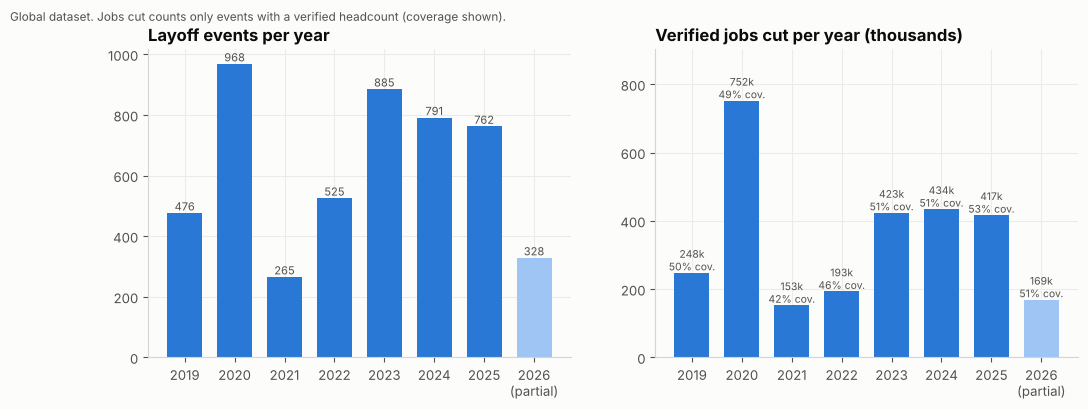

,event_year,events,events_with_headcount,verified_jobs_cut,median_cut,headcount_coverage_pct,share_of_events_pct,permanent_events,furlough_events,partial_year
0,2019,476,238,247634,200.0,50.0,9.5,472,4,False
1,2020,968,473,751961,300.0,48.9,19.4,863,105,False
2,2021,265,111,152748,210.0,41.9,5.3,258,7,False
3,2022,525,240,193251,142.0,45.7,10.5,523,2,False
4,2023,885,448,423496,169.0,50.6,17.7,882,3,False
5,2024,791,405,434305,175.0,51.2,15.8,787,4,False
6,2025,762,407,416695,200.0,53.4,15.2,754,8,False
7,2026,328,167,168818,153.0,50.9,6.6,328,0,True


In [5]:
yearly = eda.yearly_summary(g)
colors = [BLUE_LIGHT if p else BLUE for p in yearly["partial_year"]]
labels = [f"{y}\n(partial)" if p else str(y) for y, p in zip(yearly["event_year"], yearly["partial_year"])]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(labels, yearly["events"], color=colors, width=0.7)
for i, v in enumerate(yearly["events"]):
    a1.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=INK_2)
a1.set_title("Layoff events per year")
a2.bar(labels, yearly["verified_jobs_cut"] / 1000, color=colors, width=0.7)
for i, (v, c) in enumerate(zip(yearly["verified_jobs_cut"], yearly["headcount_coverage_pct"])):
    a2.text(i, v / 1000, f"{v/1000:,.0f}k\n{c:.0f}% cov.", ha="center", va="bottom", fontsize=7.5, color=INK_2)
a2.set_title("Verified jobs cut per year (thousands)")
a2.set_ylim(0, yearly["verified_jobs_cut"].max() / 1000 * 1.2)
fig.suptitle("Global dataset. Jobs cut counts only events with a verified headcount (coverage shown).", x=0.01, ha="left", fontsize=8.5, color=INK_2)
save(fig, "03_02_yearly_events_and_jobs", yearly)
yearly

In [6]:
# Validation: yearly totals reconcile with the canonical table
assert yearly["events"].sum() == len(g)
assert yearly["verified_jobs_cut"].sum() == g["employees_laid_off"].sum()
assert yearly["events_with_headcount"].sum() == g["employees_laid_off"].notna().sum() == 2489
print("yearly totals reconcile: 5,000 events,", f"{int(yearly['verified_jobs_cut'].sum()):,} verified jobs from 2,489 events")

yearly totals reconcile: 5,000 events, 2,788,908 verified jobs from 2,489 events


## 4. Industries: ranking and change over time

**Objective.** Rank industry groups by number of events and see how each group's share changed by year. **Unknown** stays in view.

**Concept.** 31% of global events have no sector, so *Unknown* is the biggest group. Hiding it would quietly inflate every other group's share.
It is drawn in grey so it reads as "missing information", not as an industry. The heatmap shows **shares within each year** (each column adds up to 100%),
so years with different totals can be compared.

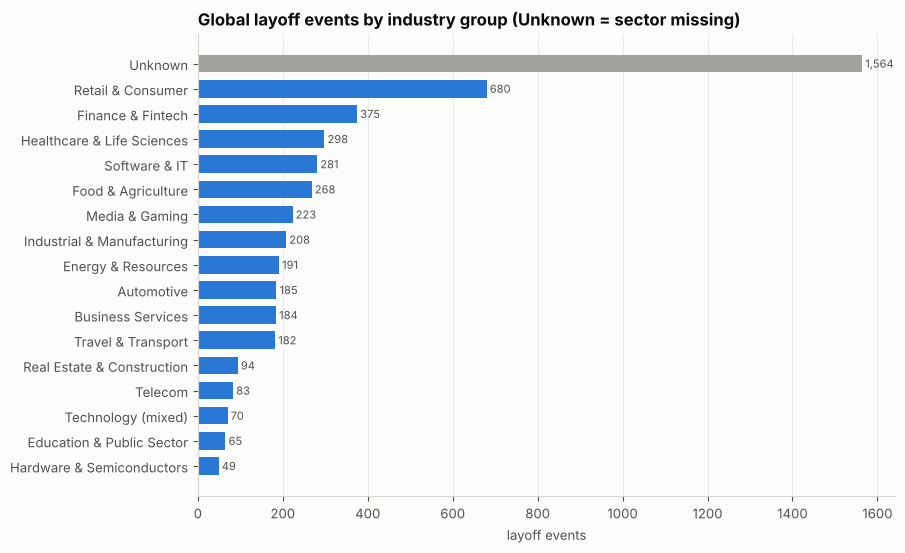

,rank_by_events,industry_group,events,share_of_events_pct,verified_jobs_cut,headcount_coverage_pct,median_cut
16,1,Unknown,1564,31.3,655977,43.5,171.0
11,2,Retail & Consumer,680,13.6,338206,53.4,200.0
4,3,Finance & Fintech,375,7.5,274074,55.5,200.0
7,4,Healthcare & Life Sciences,298,6.0,84066,53.0,103.0
12,5,Software & IT,281,5.6,196299,54.1,200.0
5,6,Food & Agriculture,268,5.4,61373,50.4,127.0
9,7,Media & Gaming,223,4.5,89068,47.5,150.0
8,8,Industrial & Manufacturing,208,4.2,230279,57.2,450.0
3,9,Energy & Resources,191,3.8,114731,51.8,300.0
0,10,Automotive,185,3.7,228895,56.2,425.0


In [7]:
industry = eda.industry_summary(g)
fig, ax = plt.subplots(figsize=(9, 6))
barh(ax, industry["industry_group"], industry["events"],
     [GREY if x == "Unknown" else BLUE for x in industry["industry_group"]])
ax.set_xlabel("layoff events")
ax.set_title("Global layoff events by industry group (Unknown = sector missing)")
save(fig, "03_03_industry_ranking", industry)
industry[["rank_by_events", "industry_group", "events", "share_of_events_pct", "verified_jobs_cut", "headcount_coverage_pct", "median_cut"]]

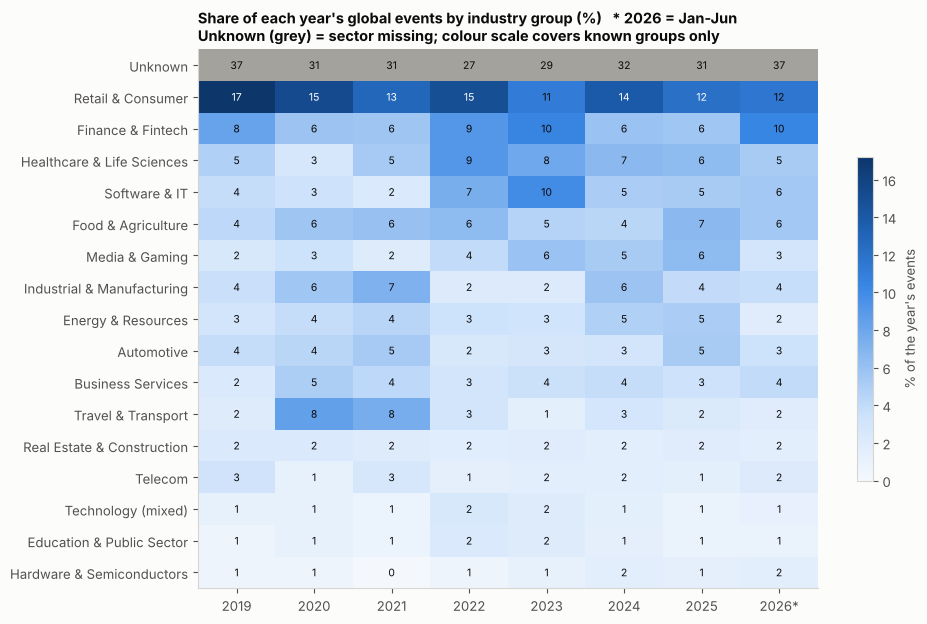

In [8]:
share = eda.industry_year_share(g)
order = industry["industry_group"].tolist()
share = share.loc[order]
fig, ax = plt.subplots(figsize=(10, 7))
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("ramp", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Unknown is drawn in neutral grey (missing information), so it is masked out of the blue scale
masked = np.ma.masked_where(np.repeat((share.index == "Unknown")[:, None], share.shape[1], axis=1), share.values)
blues.set_bad(GREY)
im = ax.imshow(masked, cmap=blues, aspect="auto", vmin=0, vmax=share.drop(index="Unknown").values.max())
ax.set_xticks(range(share.shape[1]), [f"{c}*" if c == eda.PARTIAL_YEAR else str(c) for c in share.columns])
ax.set_yticks(range(share.shape[0]), share.index)
ax.grid(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if (v > 12 and share.index[i] != "Unknown") else INK)
ax.set_title("Share of each year's global events by industry group (%)   * 2026 = Jan-Jun\nUnknown (grey) = sector missing; colour scale covers known groups only", fontsize=10.5)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of the year's events")
save(fig, "03_04_industry_share_by_year", share.reset_index())

In [9]:
# Validation: every year's shares add up to 100% (allowing for rounding), and Unknown is included
assert (share.sum().round(0).between(99, 101)).all()
assert "Unknown" in share.index and industry["events"].sum() == len(g)
print("industry tables reconcile: 17 groups incl. Unknown =", industry["events"].sum(), "events")

industry tables reconcile: 17 groups incl. Unknown = 5000 events


## 5. Countries and regions

**Objective.** Compare regions and countries, keeping missing and unresolved countries visible.

**Concept.** `country` is **where the layoff happened** (decision A-05). It is not the company's headquarters.
- **Unknown** (470 events) means the source gave no country.
- **Unresolved** (6 events) means the value is a state or fragment such as `Arizona` or `Sa`. This is still open with you, so the values are shown and not guessed.
- The US-share chart divides by events **with a known country**, so missing countries don't drag the share down.

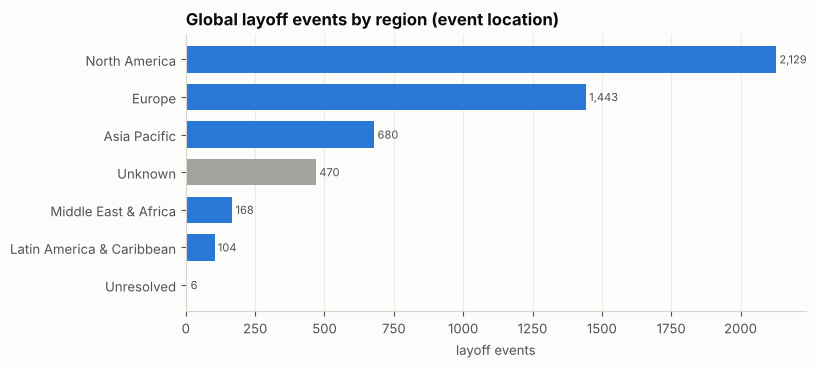

,region,events,events_with_headcount,verified_jobs_cut,median_cut,headcount_coverage_pct,share_of_events_pct
4,North America,2129,1177,1188509,152.0,55.3,42.6
1,Europe,1443,718,852983,279.5,49.8,28.9
0,Asia Pacific,680,314,374759,228.0,46.2,13.6
5,Unknown,470,161,265700,150.0,34.3,9.4
3,Middle East & Africa,168,74,53274,225.5,44.0,3.4
2,Latin America & Caribbean,104,43,53458,190.0,41.3,2.1
6,Unresolved,6,2,225,112.5,33.3,0.1


In [10]:
regions = eda.region_summary(g)
fig, ax = plt.subplots(figsize=(8, 3.6))
barh(ax, regions["region"], regions["events"], [GREY if r in ("Unknown", "Unresolved") else BLUE for r in regions["region"]])
ax.set_xlabel("layoff events")
ax.set_title("Global layoff events by region (event location)")
save(fig, "03_05_region_events", regions)
regions

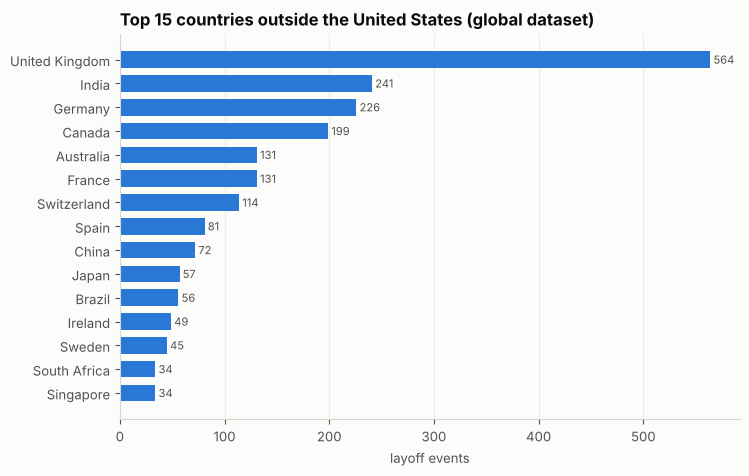

Not shown above: 1917 US events, 470 with no country


,country,region,events,events_with_headcount,verified_jobs_cut,country_status
108,Unknown,Unknown,470,161,265700,missing
2,Arizona,Unresolved,1,0,<NA>,not a country (flagged)
66,New York,Unresolved,1,0,<NA>,not a country (flagged)
64,Nevada,Unresolved,1,1,100,not a country (flagged)
80,Quebec,Unresolved,1,0,<NA>,not a country (flagged)
85,Sa,Unresolved,1,0,<NA>,not a country (flagged)
81,Rhode Island,Unresolved,1,1,125,not a country (flagged)


In [11]:
countries = eda.country_summary(g)
top_non_us = countries[(countries["country_status"] == "ok") & (countries["country"] != "United States")].head(15)
fig, ax = plt.subplots(figsize=(8, 5))
barh(ax, top_non_us["country"], top_non_us["events"], BLUE)
ax.set_xlabel("layoff events")
ax.set_title("Top 15 countries outside the United States (global dataset)")
save(fig, "03_06_top_countries_outside_us", top_non_us)
print("Not shown above:", int(countries.loc[countries["country"] == "United States", "events"].iloc[0]), "US events,",
      int(countries.loc[countries["country"] == "Unknown", "events"].iloc[0]), "with no country")
countries[countries["country_status"] != "ok"][["country", "region", "events", "events_with_headcount", "verified_jobs_cut", "country_status"]]

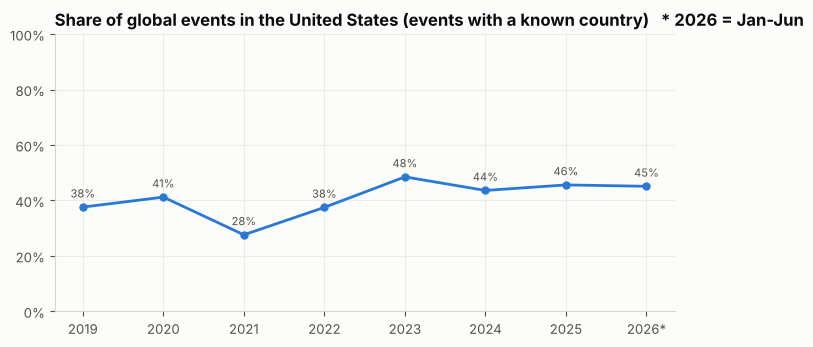

In [12]:
us = eda.us_share_by_year(g)
fig, ax = plt.subplots(figsize=(8, 3.6))
us_x = [f"{y}*" if y == eda.PARTIAL_YEAR else str(y) for y in us["event_year"]]
ax.plot(us_x, us["us_share_pct"], color=BLUE, linewidth=2, marker="o", markersize=5)
for x_, v in zip(us_x, us["us_share_pct"]):
    ax.text(x_, v + 3.5, f"{v:.0f}%", ha="center", fontsize=8, color=INK_2)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title("Share of global events in the United States (events with a known country)   * 2026 = Jan-Jun")
save(fig, "03_07_us_share_by_year", us)
assert us["events_known_country"].sum() + us["events_missing_country"].sum() == len(g)

## 6. How big are layoffs? Size bands and workforce percentage

**Objective.** Describe the size of layoffs in people and as a share of the workforce, using **only rows where the number is known**.

**Concept.** Most layoffs are small, but a few are huge (the largest verified cut in this sample is 80,000). That makes the **average misleading**, so we use the **median** and size bands.
The two charts cover **different subsets**: 2,489 events have a verified headcount and 1,121 have a workforce %. Missing rows are not counted in any band.

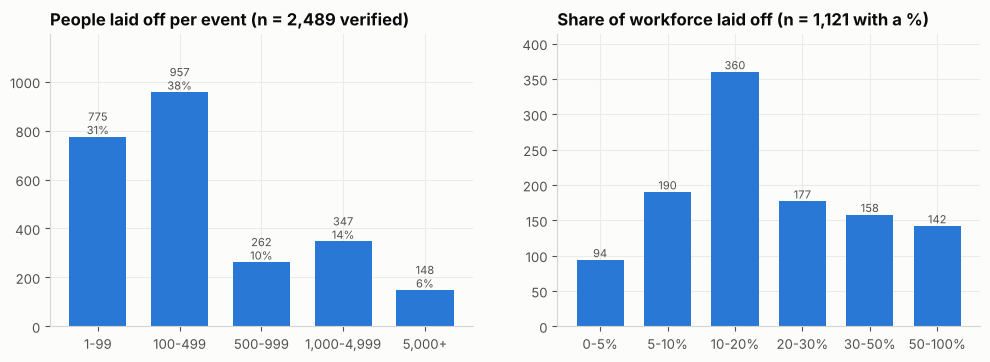

,measure,rows_with_value,rows_missing,median,mean,max
0,people laid off (verified),2489,2511,200.0,1120.5,80000.0
1,workforce %,1121,3879,15.0,22.1,95.0


In [13]:
bands = eda.size_band_summary(g)
pct_bands = eda.pct_summary(g)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.bar(bands["size_band"], bands["events"], color=BLUE, width=0.7)
for i, (v, s) in enumerate(zip(bands["events"], bands["share_of_verified_pct"])):
    a1.text(i, v, f"{v:,}\n{s:.0f}%", ha="center", va="bottom", fontsize=8, color=INK_2)
a1.set_ylim(0, bands["events"].max() * 1.25)
a1.set_title(f"People laid off per event (n = {bands['events'].sum():,} verified)")
a2.bar(pct_bands["workforce_pct_band"], pct_bands["events"], color=BLUE, width=0.7)
for i, v in enumerate(pct_bands["events"]):
    a2.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=INK_2)
a2.set_ylim(0, pct_bands["events"].max() * 1.15)
a2.set_title(f"Share of workforce laid off (n = {pct_bands['events'].sum():,} with a %)")
save(fig, "03_08_size_and_pct_distribution", pd.concat([bands.assign(chart="size_band"), pct_bands.assign(chart="pct_band")]))

h = g["employees_laid_off"].dropna()
p = g["workforce_pct"].dropna()
pd.DataFrame({"measure": ["people laid off (verified)", "workforce %"], "rows_with_value": [len(h), len(p)],
              "rows_missing": [g["employees_laid_off"].isna().sum(), g["workforce_pct"].isna().sum()],
              "median": [h.median(), p.median()], "mean": [round(h.mean(), 1), round(p.mean(), 1)], "max": [h.max(), p.max()]})

In [14]:
assert bands["events"].sum() == g["employees_laid_off"].notna().sum()       # missing rows are not in any band
assert pct_bands["events"].sum() == g["workforce_pct"].notna().sum()
print("size and % distributions use only known values:", bands["events"].sum(), "and", pct_bands["events"].sum())

size and % distributions use only known values: 2489 and 1121


## 7. Data quality and missingness

**Objective.** Show how complete each important field is and how many records carry each quality flag, so every chart above can be read with the right level of trust.

**Concept.** A quality flag marks something to be aware of; it does not mean the row is wrong. "Not computed" means the check doesn't apply to that source
(for example, the tech file has no news URLs), and that is different from "checked and fine".

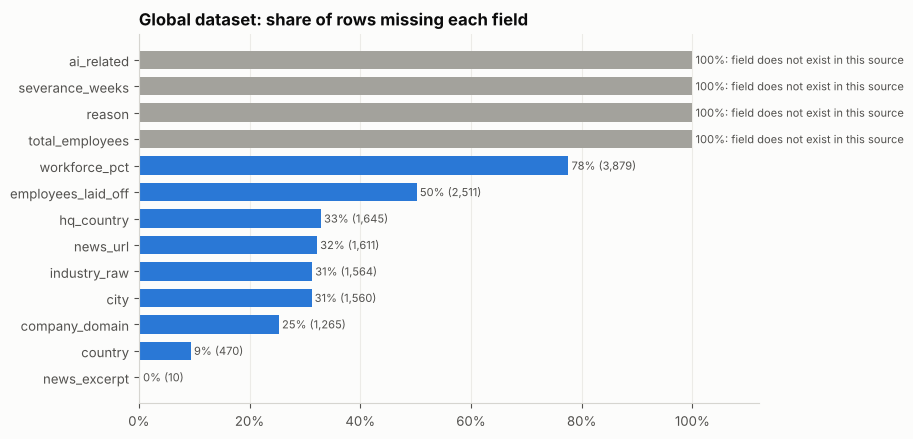

source_dataset,fliar_global_sample,tech_layoffs_2025_2026
column,,
ai_related,100.0,0.0
city,31.2,0.0
company_domain,25.3,100.0
country,9.4,0.0
employees_laid_off,50.2,0.0
hq_country,32.9,100.0
industry_raw,31.3,0.0
news_excerpt,0.2,100.0
news_url,32.2,100.0


In [15]:
fields = ["employees_laid_off", "workforce_pct", "industry_raw", "country", "hq_country", "city", "company_domain",
          "news_url", "news_excerpt", "total_employees", "reason", "severance_weeks", "ai_related"]
miss = eda.missingness(events, fields)
mg = miss[miss["source_dataset"] == eda.GLOBAL].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(mg))
ax.barh(y, mg["missing_pct"], color=[GREY if v == 100 else BLUE for v in mg["missing_pct"]], height=0.7)
ax.set_yticks(y, mg["column"])
ax.set_xlim(0, 112)
ax.grid(axis="y", visible=False)
for yi, v, m in zip(y, mg["missing_pct"], mg["missing"]):
    ax.text(v, yi, f" {v:.0f}% ({m:,})" if v < 100 else " 100%: field does not exist in this source", va="center", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title("Global dataset: share of rows missing each field")
save(fig, "03_09_missingness_global", miss)
miss.pivot(index="column", columns="source_dataset", values="missing_pct")

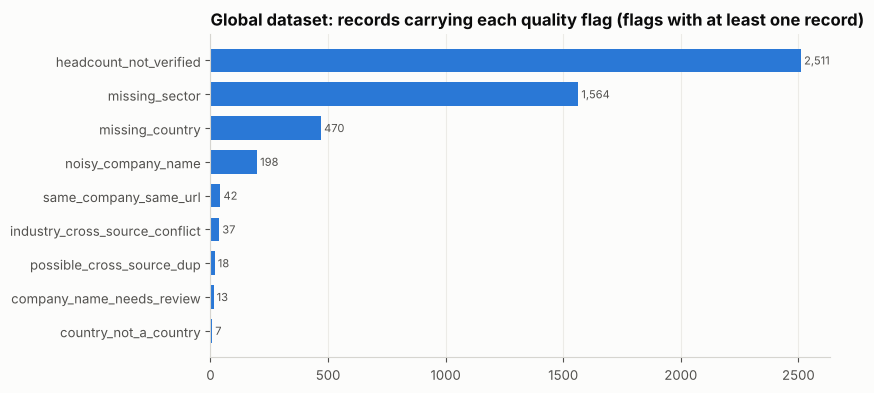

source_dataset,fliar_global_sample,tech_layoffs_2025_2026
flag,,
qc_company_name_needs_review,13,0
qc_country_not_a_country,7,0
qc_date_after_audit_date,0,0
qc_date_outside_expected_range,0,0
qc_date_unparseable,0,0
qc_headcount_math_gap_gt10pct,0,0
qc_headcount_not_positive,0,0
qc_headcount_not_verified,2511,0
qc_headcount_status_conflict,0,0


In [16]:
qc = eda.qc_flag_summary(events)
qg = qc[(qc["source_dataset"] == eda.GLOBAL) & (qc["true"] > 0)].sort_values("true")
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(qg))
ax.barh(y, qg["true"], color=BLUE, height=0.7)
ax.set_yticks(y, qg["flag"].str.replace("qc_", ""))
ax.grid(axis="y", visible=False)
for yi, v in zip(y, qg["true"]):
    ax.text(v, yi, f" {v:,}", va="center", fontsize=8, color=INK_2)
ax.set_title("Global dataset: records carrying each quality flag (flags with at least one record)")
save(fig, "03_10_quality_flags_global", qc)
qc.pivot(index="flag", columns="source_dataset", values="true")

In [17]:
# Validation: flag counts equal the canonical columns, and 'not computed' is kept separate from False
for _, r in qc.iterrows():
    part = events[events["source_dataset"] == r["source_dataset"]][r["flag"]]
    assert r["true"] == part.sum() and r["not_computed"] == part.isna().sum()
print("quality-flag counts reconcile with layoff_events.csv")

quality-flag counts reconcile with layoff_events.csv


## 8. Sensitivity: do duplicates or furloughs change the trend?

**Objective.** Check that the yearly trend isn't driven by records we're unsure about. **Nothing is deleted.** Each column is a *what-if* count.

**Concept.**
- **Furloughs** are temporary layoffs, and most of them fall in 2020.
- **Internal duplicates** are 42 global rows that share a news article with another row of the same company.
- **Cross-source duplicate candidates** are global rows linked to a tech row in Phase 1, and they are still pending your review.

If a trend only holds with these rows included, it isn't a robust finding.

In [18]:
sens = eda.sensitivity_by_year(g)
sens["furlough_share_pct"] = (100 * (sens["all_events"] - sens["excl_furloughs"]) / sens["all_events"]).round(1)
sens.to_csv(EDA_DIR / "03_11_sensitivity_by_year.csv", index=False)
sens

,event_year,all_events,excl_furloughs,excl_internal_duplicates,excl_cross_source_duplicate_candidates,furlough_share_pct
0,2019,476,472,471,476,0.8
1,2020,968,863,962,968,10.8
2,2021,265,258,260,265,2.6
3,2022,525,523,521,525,0.4
4,2023,885,882,879,880,0.3
5,2024,791,787,777,789,0.5
6,2025,762,754,760,753,1.0
7,2026,328,328,328,326,0.0


In [19]:
assert (sens["all_events"] == yearly["events"].values).all()
assert sens["all_events"].sum() - sens["excl_internal_duplicates"].sum() == int(g["possible_internal_duplicate"].sum()) == 42
assert sens["all_events"].sum() - sens["excl_cross_source_duplicate_candidates"].sum() == int(g["possible_duplicate_group"].notna().sum()) == 18
print("sensitivity counts reconcile; duplicate candidates remain in the main counts")

sensitivity counts reconcile; duplicate candidates remain in the main counts


## 9. Separate analysis: the 35 tech records (lower confidence)

> **Read with caution.** This file's **source is unknown**, it has only **35 rows**, and Phase 1 found that **6 of its dates are suspect**
> (Twitch, Dell, Roku, Accenture, Unity, Adobe: same headcount as a 2023-24 global event, but dated 2025-26). Its numbers are *reported*, not verified.
> Nothing here is combined with the global analysis, and nothing here supports market-wide conclusions.
> It is useful for one thing the global file lacks: **reasons, departments, severance and an AI flag**.

**Objective.** Describe what this small file says about reasons, departments, severance and AI involvement.

**Concept.** Departments come from the bridge table. One event can involve two departments, so we count **events involving** each department (`COUNT DISTINCT`), and headcounts are never split or summed by department.
Charts in this section are **orange**, so they are never mistaken for global charts.

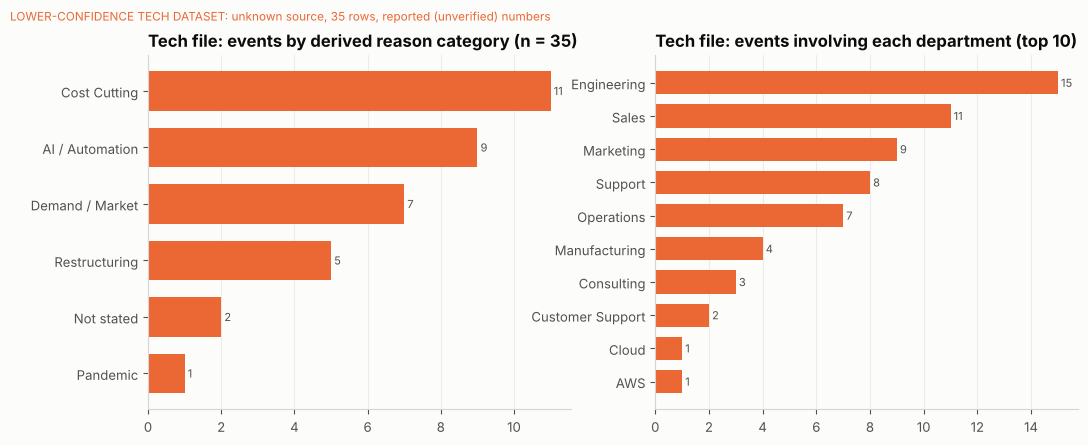

,department,events_involving,weighted_events
0,Engineering,15,7.5
1,Sales,11,5.5
2,Marketing,9,4.5
3,Support,8,4.0
4,Operations,7,3.5
5,Manufacturing,4,2.0
6,Consulting,3,1.5
7,Customer Support,2,1.0
8,Cloud,1,0.5
9,AWS,1,0.5


In [20]:
reasons = eda.tech_reason_summary(t)
dept = eda.tech_department_summary(departments)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
barh(a1, reasons["reason_category_derived"], reasons["events"], ORANGE)
a1.set_title("Tech file: events by derived reason category (n = 35)")
d10 = dept.head(10)
barh(a2, d10["department"], d10["events_involving"], ORANGE)
a2.set_title("Tech file: events involving each department (top 10)")
fig.suptitle("LOWER-CONFIDENCE TECH DATASET: unknown source, 35 rows, reported (unverified) numbers", x=0.01, ha="left", fontsize=8.5, color=ORANGE)
save(fig, "03_T1_tech_reasons_and_departments", pd.concat([reasons.assign(chart="reason"), dept.assign(chart="department")]))
dept

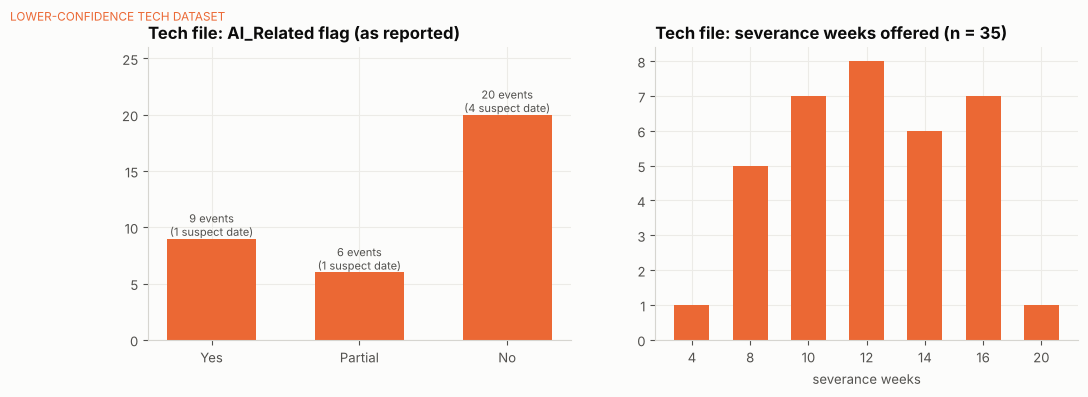

,ai_related,events,reported_laid_off,median_pct_workforce,median_severance_weeks,suspect_dates
0,Yes,9,21720,5.5,12.0,1
1,Partial,6,48772,8.0,11.0,1
2,No,20,83030,15.0,12.0,4


In [21]:
ai = eda.tech_ai_summary(t)
sev = eda.tech_severance_summary(t)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.bar(ai["ai_related"], ai["events"], color=ORANGE, width=0.6)
for i, (v, s) in enumerate(zip(ai["events"], ai["suspect_dates"])):
    a1.text(i, v, f"{v} events\n({s} suspect date)", ha="center", va="bottom", fontsize=8, color=INK_2)
a1.set_ylim(0, ai["events"].max() * 1.3)
a1.set_title("Tech file: AI_Related flag (as reported)")
a2.bar(sev["severance_weeks"].astype(str), sev["events"], color=ORANGE, width=0.6)
a2.set_xlabel("severance weeks")
a2.set_title("Tech file: severance weeks offered (n = 35)")
fig.suptitle("LOWER-CONFIDENCE TECH DATASET", x=0.01, ha="left", fontsize=8.5, color=ORANGE)
save(fig, "03_T2_tech_ai_and_severance", pd.concat([ai.assign(chart="ai_related"), sev.assign(chart="severance")]))
ai

In [22]:
t[t["qc_suspect_date"]][["event_key", "company_name", "event_date_raw", "employees_laid_off", "ai_related", "date_flag_reason"]]

,event_key,company_name,event_date_raw,employees_laid_off,ai_related,date_flag_reason
5001,T-00002,Twitch,2025-01-09,500,No,headcount 500 within 0.0% of global G-03089 (5...
5006,T-00007,Dell,2025-02-05,6650,No,headcount 6650 within 1.5% of global G-02557 (...
5012,T-00013,Roku,2025-03-30,360,No,headcount 360 within 0.0% of global G-02887 (3...
5013,T-00014,Accenture,2025-03-30,19000,Partial,headcount 19000 within 0.0% of global G-02252 ...
5017,T-00018,Unity,2025-05-08,1800,No,headcount 1800 within 0.0% of global G-03142 (...
5030,T-00031,Adobe,2026-01-28,680,Yes,headcount 680 within 0.0% of global G-02463 (6...


In [23]:
assert reasons["events"].sum() == ai["events"].sum() == sev["events"].sum() == len(t) == 35
assert dept["events_involving"].sum() == len(departments) and round(dept["weighted_events"].sum(), 9) == 35
assert ai["suspect_dates"].sum() == 6
print("tech tables reconcile: 35 events, 70 department links, weighted department total = 35")

tech tables reconcile: 35 events, 70 department links, weighted department total = 35


## 10. Key numbers used in the findings

**Objective.** Print every number quoted in the findings below directly from the data, so the text can be checked.

In [24]:
y = yearly.set_index("event_year")
key = {
    "peak year (events)": int(y["events"].idxmax()), "events in peak year": int(y["events"].max()),
    "2020 furloughs": int(y.loc[2020, "furlough_events"]), "2021 events": int(y.loc[2021, "events"]),
    "2023 events": int(y.loc[2023, "events"]), "peak month": peak["month"], "peak month events": int(peak["events"]),
    "headcount coverage (all years)": f"{100 * g['employees_laid_off'].notna().mean():.1f}%",
    "median verified cut": int(g["employees_laid_off"].median()),
    "share of verified cuts under 500": f"{bands.loc[:1, 'events'].sum() / bands['events'].sum() * 100:.1f}%",
    "share of verified cuts 5,000+": f"{bands.loc[4, 'share_of_verified_pct']}%",
    "median workforce %": float(g["workforce_pct"].median()),
    "Unknown industry share": f"{industry.loc[industry['industry_group'] == 'Unknown', 'share_of_events_pct'].iloc[0]}%",
    "top known industry": industry[industry["industry_group"] != "Unknown"].iloc[0]["industry_group"],
    "US share range (known country)": f"{us['us_share_pct'].min()}% - {us['us_share_pct'].max()}%",
    "top country outside US": top_non_us.iloc[0]["country"],
    "tech AI_Related Yes / Partial / No": "/".join(str(v) for v in ai["events"]),
}
pd.Series(key, name="value").to_frame()

,value
peak year (events),2020
events in peak year,968
2020 furloughs,105
2021 events,265
2023 events,885
peak month,2020-04
peak month events,165
headcount coverage (all years),49.8%
median verified cut,200
share of verified cuts under 500,69.6%


## 11. Findings: what the data supports, and its limits

Every number below is printed in Section 10 or in the table under the chart it refers to.

### A. Supported observations (global dataset, 5,000-event sample)

| # | Observation | Evidence | How robust |
|---|---|---|---|
| F1 | **2020 had the most layoff events (968)**, peaking in **April 2020 (165 events)**. Events then fell to a low in 2021 (265). | Charts 03_01, 03_02 | **Depends on furloughs.** Without the 105 furloughs (temporary layoffs), 2020 has 863 events, slightly **below 2023 (885)**. So 2020 is the peak year only if furloughs are counted (Section 8). |
| F2 | **Layoff activity returned at a high level from 2023 (885 events) and stayed there through 2024 (791) and 2025 (762).** The 2023-2025 monthly average is about 55-95 events, against about 40 before COVID. | Charts 03_01, 03_02 | Robust to excluding duplicate candidates and furloughs (at most 14 events change in any year, other than the 2020 furloughs). |
| F3 | **2020 had the most disclosed jobs cut (about 752k, 90% interval about 553k-979k)**, and that lead holds against every other year. 2023, 2024 and 2025 were each about 417-434k, with overlapping intervals, so **the sample cannot rank 2023-2025 against each other**. | Chart 03_02; notebook 05 | **Lower bounds, and only 2020 vs other years is supported.** Only about half of events have a disclosed headcount (42%-53% by year). Because the sample keeps or drops whole companies, a few very large cuts decide each year's total: the sample-to-full ratio for disclosed jobs swings from 0.225 to 0.341 by year, and the full data orders these years 2023 > 2025 > 2024, while the sample orders them 2024 > 2023 > 2025. Intervals are a company-cluster bootstrap (notebook 05). |
| F4 | **Most layoffs are small.** The median verified cut is **200 people**, and **70%** of verified events cut fewer than 500 people. A few very large events (5,000+, **6%**) pull the average up to about 1,120. | Chart 03_08 | Robust within the 2,489 events with a verified headcount. Events without a headcount may differ (e.g. smaller companies may report fewer numbers). |
| F5 | **The typical event cut 10-20% of the workforce** (median **15%**). | Chart 03_08 | **Limited.** Only 1,121 of 5,000 events (22%) report a percentage. |
| F6 | **Retail & Consumer is the largest known industry group** (680 events, 13.6%), ahead of Finance & Fintech (375) and Healthcare (298). | Charts 03_03, 03_04 | Holds in every year, but **31% of events have no sector**, so the gaps between the smaller groups are not reliable. |
| F7 | **Travel & Transport's share jumped in 2020-21** (8% of events, against 1-3% in other years). **Software & IT peaked in 2023 (10%).** | Chart 03_04 | Moderate. These are shares of a sample, and group sizes are small in some years. |
| F8 | **The United States has the most events (1,917).** Its share of events with a known country rose from **about 28% in 2021 to about 44-48% in 2023-2026**. The United Kingdom (564), India (241) and Germany (226) follow. | Charts 03_06, 03_07 | Moderate. `country` is the event location. 470 events (9%) have no country, and 6 values are unresolved. Coverage of non-English sources is unknown. |

### B. Limitations (read before quoting any number)

1. **Sample, not the market.** The global file is a 26% sample of the source (Fliar Research). Counts describe the sample. Multiplying by about 4 to get a "market total" is not supported.
2. **Jobs-cut totals are lower bounds.** 2,511 of 5,000 events (50.2%) have no verified headcount, and they were **left missing**, not counted as 0.
3. **Unknown is the biggest industry group (31%).** Industry rankings below the top 2-3 groups could change if the sectors were known.
4. **2026 is partial (Jan to 14 Jun).** Also, **May and June 2026 look incomplete** (12 and 23 events, against 60-90 in earlier months). This is probably a collection lag in the source, not a real drop. **Do not read it as a decline.**
5. **Country questions are still open.** 6 event-country values (`Arizona`, `Nevada`, `New York`, `Rhode Island`, `Quebec`, `Sa`) are shown as *Unresolved* and are not reassigned, pending your decision.
6. **Duplicates are not resolved.** 42 internal duplicate flags and 18 cross-source candidates remain in all counts. Section 8 shows they change no conclusion.
7. **Correlation only.** Nothing here explains *why* layoffs happen. The global file has no reason field, and the reason category is derived from keywords and is "Not stated" for most global rows.

### C. Separate: tech file (35 rows, unknown source, lower confidence)

| # | Observation (as reported in the file) | Caveat |
|---|---|---|
| T1 | 9 of 35 events are marked `AI_Related = Yes` and 6 `Partial`. | The flag comes from an unknown source with no stated definition. One "Yes" event (Adobe) has a suspect date. |
| T2 | **Engineering** is the department most often involved (15 of 35 events), followed by Sales (11) and Marketing (9). | Counts events involving a department. Headcounts are not split by department. |
| T3 | Severance ranges from **4 to 20 weeks** (median 12). | Unverified. 35 rows from 2025-26 only. |
| T4 | The derived reason categories are mostly cost cutting (11) and AI / automation (9). | Keyword-derived (rule A-10). |

**This file supports no market-wide claims.** 6 of its 35 dates are flagged as suspect, and its rows are not combined with the global analysis.